---
title: "Wycena opcji barierowej Down-and-Out Put za pomocą PyMPDATA"
author: "Kamil Kasperek"
lang: pl
format:
  pdf:
    geometry: margin=0.55in
    fontsize: 9.5pt
    echo: false
    warning: false
---

### Cel pracy i pytanie badawcze
Celem eksperymentu jest numeryczna wycena europejskiej opcji sprzedaży z dolną barierą wyłączającą (**Down-and-Out Put**) poprzez sprowadzenie modelu Blacka-Scholesa do równania adwekcji-dyfuzji i rozwiązanie go za pomocą biblioteki `PyMPDATA`. 

**Pytanie badawcze:** *Jak dobrze schemat 2. rzędu `MPDATA` radzi sobie ze stromym spadkiem wartości przy barierze $B$ oraz wyznaczeniem współczynnika Delta ($\Delta = \partial V / \partial S$) na różnych rozdzielczościach siatki w porównaniu ze zwykłym schematem `upwind`?*

In [1]:
import numpy as np
from matplotlib import pyplot
from PyMPDATA import ScalarField, Solver, Stepper, VectorField, Options, boundary_conditions
from scipy.special import erf

## 1. Opcja Down-and-Out Put i zabezpieczanie portfela (Delta)
Opcja *Down-and-Out Put* daje prawo do sprzedaży aktywa po cenie wykonania $K$ w chwili $T$, o ile jego kurs $S(t)$ przez cały czas trwania umowy nie spadnie do dolnej bariery wyłączającej $B$ (co natychmiast zeruje wartość kontraktu). Kluczowym parametrem zabezpieczania portfela (*delta-hedging*) jest współczynnik wrażliwości **Delta** ($\Delta = \partial V / \partial S$), który tuż przy barierze $B$ osiąga bardzo stromy gradient, stanowiąc wymagający test dla schematów numerycznych.

## 2. Model matematyczny i metodyka numeryczna
Po wprowadzeniu zmiennej logarytmicznej $x = \ln(S/K)$ oraz czasu wstecznego $\tau = T - t$ równanie Blacka-Scholesa przyjmuje postać jednowymiarowego równania adwekcji-dyfuzji:
$$\frac{\partial \psi}{\partial \tau} + \left(\frac{1}{2}\sigma^2 - r\right)\frac{\partial \psi}{\partial x} = \frac{1}{2}\sigma^2 \frac{\partial^2 \psi}{\partial x^2}$$
gdzie $\psi(x, \tau) = e^{r\tau} V(S, t)$ oznacza zdyskontowaną wartość opcji, dyfuzja odpowiada zmienności $\sigma$, a adwekcja dryfowi rynkowemu. Barierę wyłączającą modelujemy jako pochłaniający warunek brzegowy Dirichleta ($\psi = 0$ dla $S \le B$). W bibliotece `PyMPDATA` człon dyfuzyjny realizowany jest przez pseudo-prędkość dyfuzyjną Smolarkiewicza (`non_zero_mu_coeff=True`), a wyniki porównywane są ze ścisłym [rozwiązaniem analitycznym](https://people.maths.ox.ac.uk/howison/barriers.pdf) opartym na zasadzie odbicia.

In [2]:
class DownAndOutPutIntegrator:
    def __init__(self, *, strike_price, barrier_price, volatility, risk_free_interest_rate, nx, options=None):
        options = options or Options(nonoscillatory=True, infinite_gauge=True, non_zero_mu_coeff=True, divergent_flow=True)

        assert options.non_zero_mu_coeff, "non_zero_mu_coeff must be True"
        assert strike_price > 0
        assert barrier_price > 0
        assert risk_free_interest_rate >= 0
        assert volatility >= 0
        assert nx > 0

        self.K = strike_price
        self.B = barrier_price
        self.r = risk_free_interest_rate
        self.sigma = volatility

        x_min = np.log(self.B / self.K)
        x_max = max(4.0 * np.log(self.K / self.B), 1.5)
        self.dx = (x_max - x_min) / nx
        self.S = self.K * np.exp(x_min + (np.arange(nx) + 0.5) * self.dx)
        self.payout = np.where((self.B < self.S) & (self.S < self.K), self.K - self.S, 0.0)

        common = {
            'halo': options.n_halo,
            'boundary_conditions': (boundary_conditions.Constant(value=0),)
        }

        self.advectee = ScalarField(**common, data=self.payout.copy())
        self.advector = VectorField(**common, data=(np.zeros(nx + 1),))
        self.solver = Solver(
            advector=self.advector,
            advectee=self.advectee,
            stepper=Stepper(n_dims=1, options=options)
        )

    def __call__(self, *, nt, T, outfreq):
        assert nt % outfreq == 0, "nt must be divisible by outfreq"
        
        dt = T / nt
        c_adv = (0.5 * self.sigma**2 - self.r) * dt / self.dx
        mu = 0.5 * self.sigma**2 * dt / (self.dx**2)
        assert abs(c_adv) + 2 * mu <= 0.5

        self.advectee.get()[:] = self.payout
        self.advector.get_component(0)[:] = c_adv

        output = [self.advectee.get().copy()]
        for step in range(1, nt // outfreq + 1):
            self.solver.advance(n_steps=outfreq, mu_coeff=(mu,))
            output.append(self.advectee.get().copy() * np.exp(-self.r * step * outfreq * dt))
        return output

In [3]:
def AnalyticalDownAndOutPutSolver(*, S, K, B, T, r, sigma):
    def N(z):
        return 0.5 * (1.0 + erf(z / np.sqrt(2.0)))

    def vanilla_put(s, strike):
        d1 = (np.log(s / strike) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
        d2 = d1 - sigma * np.sqrt(T)
        return strike * np.exp(-r * T) * N(-d2) - s * N(-d1)

    def binary_put(s, strike):
        d2 = (np.log(s / strike) + (r - 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
        return np.exp(-r * T) * N(-d2)

    def truncated_put(s):
        return vanilla_put(s, K) - vanilla_put(s, B) - (K - B) * binary_put(s, B)

    power = 2.0 * r / (sigma**2) - 1.0
    result = truncated_put(S) - (B / S)**power * truncated_put((B**2) / S)
    return np.where(S > B, result, 0.0)

In [4]:
def pad_barrier(S_arr, V_arr, barrier, s_min=60.0):
    return np.concatenate(([s_min, barrier], S_arr)), np.concatenate(([0.0, 0.0], V_arr))

In [5]:
def plot_results(*, integ_MPDATA, output_MPDATA, output_upwind, S_fine, analytical_price, analytical_delta, nx, nt, max_Delta=None):
    S = integ_MPDATA.S
    barrier = integ_MPDATA.B
    S_plot, payoff_plot = pad_barrier(S, output_MPDATA[0], barrier)
    _, mpdata_mid = pad_barrier(S, output_MPDATA[len(output_MPDATA) // 2], barrier)
    _, upwind_mid = pad_barrier(S, output_upwind[len(output_upwind) // 2], barrier)
    _, upwind_end = pad_barrier(S, output_upwind[-1], barrier)
    _, mpdata_end = pad_barrier(S, output_MPDATA[-1], barrier)
    S_fine_plot, exact_plot = pad_barrier(S_fine, analytical_price, barrier)

    mpdata_delta = np.gradient(output_MPDATA[-1], S)
    upwind_delta = np.gradient(output_upwind[-1], S)

    fig, (ax_price, ax_delta) = pyplot.subplots(1, 2, figsize=(11, 3.5))

    ax_price.plot(S_plot, payoff_plot, linestyle=':', color='gray', label='Payoff (t = T)')
    ax_price.plot(S_plot, mpdata_mid, linestyle='-.', color='tab:cyan', label='MPDATA (t = 0.5 T)')
    ax_price.plot(S_plot, upwind_mid, linestyle='-.', color='tab:orange', label='upwind (t = 0.5 T)')
    ax_price.plot(S_plot, upwind_end, linestyle='--', color='tab:red', label='upwind (t = 0)')
    ax_price.plot(S_plot, mpdata_end, color='tab:blue', linewidth=2, label='MPDATA (t = 0)')
    ax_price.plot(S_fine_plot, exact_plot, linestyle='--', color='black', linewidth=1.2, label='Analytical (t = 0)')

    ax_delta.plot(S, upwind_delta, linestyle='--', color='tab:orange', label='upwind (t = 0)')
    ax_delta.plot(S, mpdata_delta, color='tab:blue', linewidth=2, label='MPDATA (t = 0)')
    ax_delta.plot(S_fine, analytical_delta, linestyle='--', color='black', linewidth=1.2, label='Analytical (t = 0)')
    ax_delta.axhline(0, color='gray', linewidth=0.8)
    if max_Delta:
        ax_delta.set_ylim(None, max_Delta)

    for ax, ylabel, title in [
        (ax_price, 'Option value V(S, t) [$]', f'Option value evolution (nx={nx}, nt={nt})'),
        (ax_delta, 'Delta Δ = ∂V / ∂S [-]', f'Portfolio sensitivity: Delta (nx={nx}, nt={nt})')
    ]:
        ax.axvline(barrier, color='green', linestyle='--', linewidth=1, label=f'Barrier B = {barrier}$')
        ax.set_xlim(75, 160)
        ax.set_xlabel('Asset price S [$]')
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.grid(True, alpha=0.3)

    ax_price.legend(fontsize=7.5, ncol=2)
    ax_delta.legend(fontsize=7.5)
    pyplot.tight_layout()
    pyplot.show()

In [6]:
def make_integrators(*, strike_price, barrier_price, 
                     risk_free_interest_rate, volatility, nx):
    integ_MPDATA = DownAndOutPutIntegrator(
        strike_price=strike_price, barrier_price=barrier_price,
        volatility=volatility, risk_free_interest_rate=risk_free_interest_rate,
        nx=nx
    )
    integ_upwind = DownAndOutPutIntegrator(
        strike_price=strike_price, barrier_price=barrier_price,
        volatility=volatility, risk_free_interest_rate=risk_free_interest_rate,
        nx=nx, options=Options(n_iters=1, non_zero_mu_coeff=True)
    )
    return integ_MPDATA, integ_upwind

In [7]:
def run_scenario(*, integ_MPDATA, integ_upwind, nt, T, outfreq):
    
    output_MPDATA = integ_MPDATA(nt=nt, T=T, outfreq=outfreq)
    output_upwind = integ_upwind(nt=nt, T=T, outfreq=outfreq)

    assert np.all(output_MPDATA[-1] >= 0.0), "Price of asset cannot be negative"
    assert np.all(output_upwind[-1] >= 0.0), "Price of asset cannot be negative"
    
    exact = AnalyticalDownAndOutPutSolver(S=integ_MPDATA.S, K=integ_MPDATA.K, 
                                          B=integ_MPDATA.B, T=T, r=integ_MPDATA.r, 
                                          sigma=integ_MPDATA.sigma)
    error_mpdata = np.sqrt(np.mean((output_MPDATA[-1] - exact)**2))
    error_upwind = np.sqrt(np.mean((output_upwind[-1] - exact)**2))
    
    return output_MPDATA, output_upwind, error_mpdata, error_upwind

## 3. Analiza zbieżności i wyniki dla scenariusza bazowego
Przetestowano półroczną opcję ($T = 0{,}5\text{ roku}$) o parametrach $K = 120\$$, $B = 80\$$, $\sigma = 35\%$ oraz $r = 5\%$ dla siatek przestrzennych $n_x \in \{50, 100, 150, 200\}$ (zapewniających co najmniej 10 komórek w aktywnym obszarze $[B, K]$) oraz kroków czasowych $n_t \in \{1250, 2250, 3000, 4000\}$. Wyznaczono błąd średniokwadratowy $L_2$ względem krzywej analitycznej oraz porównano profile ceny i współczynnika $\Delta$ dla najgęstszej siatki.

In [8]:
strike_price = 120
barrier_price = 80
volatility = 0.35
risk_free_interest_rate = 0.05
T = 0.5
nx = [50, 100, 150, 200]
nt = [1250, 2250, 3000, 4000]

S_fine = np.linspace(barrier_price, 200.0, 1000)
analytical_price = AnalyticalDownAndOutPutSolver(S=S_fine, K=strike_price, B=barrier_price, T=T, r=risk_free_interest_rate, sigma=volatility)
analytical_delta = np.gradient(analytical_price, S_fine)

errors_mpdata = np.empty((len(nx), len(nt)))
errors_upwind = np.empty((len(nx), len(nt)))

for i, nx_i in enumerate(nx):
    integ_MPDATA, integ_upwind = make_integrators(strike_price=strike_price, barrier_price=barrier_price,
                                                 risk_free_interest_rate=risk_free_interest_rate,
                                                 volatility=volatility, nx=nx_i)
    for j, nt_i in enumerate(nt):
        _, _, errors_mpdata[i, j], errors_upwind[i, j] = run_scenario(integ_MPDATA=integ_MPDATA, integ_upwind=integ_upwind,
                                                                      nt=nt_i, T=T, outfreq=nt_i)

In [9]:
assert np.all(errors_mpdata < errors_upwind), "MPDATA should beat upwind on all grids"
assert errors_mpdata[-1, -1] < 0.01, f"Finest grid error too large: {errors_mpdata[-1, -1]:.4f}"
assert np.all(np.diff(errors_mpdata, axis=0) < 0), "Error must strictly decrease with finer spatial grid nx"
assert np.all(np.diff(errors_mpdata[-1]) < 0), "Error on finest nx must decrease with finer nt"

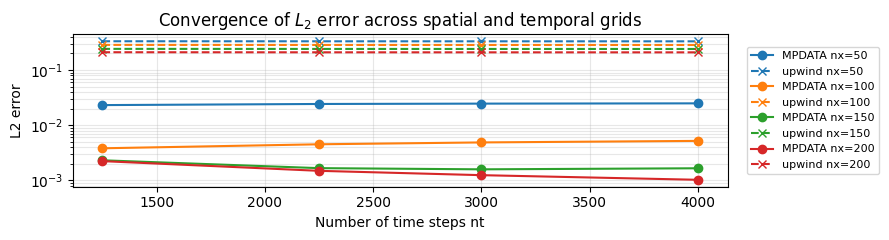

In [10]:
fig, ax = pyplot.subplots(figsize=(9, 2.5))
for i, nx_val in enumerate(nx):
    ax.plot(nt, errors_mpdata[i], f'C{i}o-', label=f'MPDATA nx={nx_val}')
    ax.plot(nt, errors_upwind[i], f'C{i}x--', label=f'upwind nx={nx_val}')
ax.set_yscale('log')
ax.set_xlabel('Number of time steps nt')
ax.set_ylabel('L2 error')
ax.set_title('Convergence of $L_2$ error across spatial and temporal grids')
ax.grid(True, which='both', alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 0.5), loc='center left', fontsize=8)
pyplot.tight_layout()
pyplot.show()

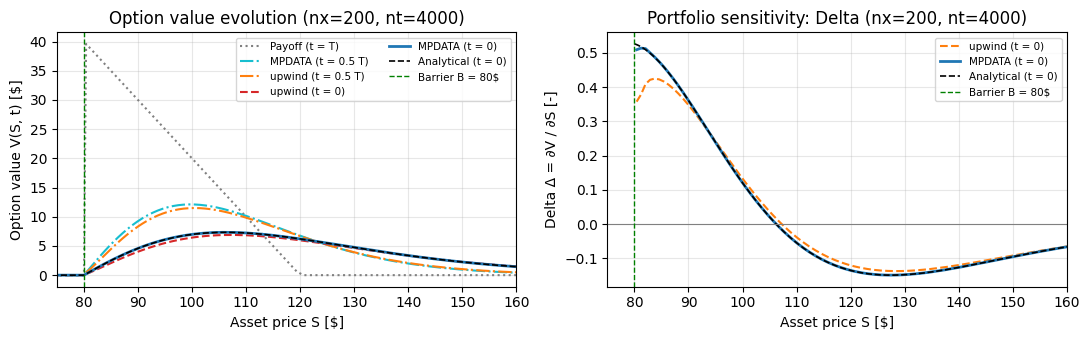

In [11]:
integ_MPDATA, integ_upwind = make_integrators(strike_price=strike_price, barrier_price=barrier_price,
                                                 risk_free_interest_rate=risk_free_interest_rate,
                                                 volatility=volatility, nx=nx[-1])

output_MPDATA, output_upwind, error_mpdata, error_upwind = run_scenario(integ_MPDATA=integ_MPDATA, integ_upwind=integ_upwind, 
                                                  nt=nt[-1], T=T, outfreq=20)

plot_results(integ_MPDATA=integ_MPDATA, output_MPDATA=output_MPDATA, output_upwind=output_upwind, S_fine=S_fine, 
             analytical_price=analytical_price, analytical_delta=analytical_delta, nx=nx[-1], nt=nt[-1])

In [12]:
from matplotlib.animation import FuncAnimation, PillowWriter

def save_animation(*, name, integ_MPDATA, output_MPDATA, output_upwind, analytical_price, S_fine, nx, nt, T):
    barrier_price = integ_MPDATA.B
    dt_frame = T / (len(output_MPDATA) - 1)
    y_max = np.max(output_MPDATA[0]) * 1.1
    S_plot, _ = pad_barrier(integ_MPDATA.S, output_MPDATA[0], barrier_price)
    S_fine_plot, exact_plot = pad_barrier(S_fine, analytical_price, barrier_price)
    
    fig, ax = pyplot.subplots(figsize=(7, 4))
    
    def update(frame):
        ax.clear()
        t_remaining = T - frame * dt_frame
        _, mpdata_frame = pad_barrier(integ_MPDATA.S, output_MPDATA[frame], barrier_price)
        _, upwind_frame = pad_barrier(integ_MPDATA.S, output_upwind[frame], barrier_price)
    
        ax.fill_between(S_plot, mpdata_frame, color='tab:blue', alpha=0.25)
        ax.plot(S_plot, mpdata_frame, color='tab:blue', linewidth=2, label='MPDATA')
        ax.plot(S_plot, upwind_frame, color='tab:orange', linestyle='--', linewidth=1.5, label='upwind')
        ax.plot(S_fine_plot, exact_plot, color='black', linestyle=':', linewidth=1.2, label='Analytical (t = 0)')
        ax.axvline(barrier_price, color='green', linestyle='--', linewidth=1.5, label=f'Barrier B = {barrier_price}$')
        ax.set_xlim(65, 200)
        ax.set_ylim(-1, y_max)
        ax.set_xlabel('Asset price S [$]')
        ax.set_ylabel('Option value V(S, t) [$]')
        ax.set_title(f'Option value evolution (nx={nx}, nt={nt}) – {t_remaining:.3f} years remaining')
        ax.grid(True, alpha=0.3)
        ax.legend(loc='upper right')
    
    anim = FuncAnimation(fig, update, frames=len(output_MPDATA), interval=80)
    anim.save(name, writer=PillowWriter(fps=15))
    pyplot.close(fig)

In [ ]:
save_animation(name="standard_animation.gif", integ_MPDATA=integ_MPDATA, output_MPDATA=output_MPDATA,
               output_upwind=output_upwind, analytical_price=analytical_price, S_fine=S_fine, nx=nx[-1], nt=nt[-1], T=T)

## 4. Scenariusz zdominowany przez adwekcję i wizualizacje dynamiczne
Oprócz wygenerowania animacji dla scenariusza bazowego (`standard_animation.gif`), zbadano przypadek silnej adwekcji przy niemal zerowej dyfuzji ($r = 0{,}30$, $\sigma = 0{,}01$, `left_advection_animation.gif`). Wysoka stopa wolna od ryzyka wymusza silny dryf w lewo ($v_{\text{adv}} = \frac{1}{2}\sigma^2 - r < 0$), przez co profil wartości opcji przesuwa się jak fala prosto w kierunku pochłaniającej bariery $B = 80\$$.

In [ ]:
strike_price = 120
barrier_price = 80
volatility = 0.01
risk_free_interest_rate = 0.30
T = 0.5
nx = nx[-1]
nt = nt[-1]
outfreq = 20

integ_MPDATA, integ_upwind = make_integrators(strike_price=strike_price, barrier_price=barrier_price, volatility=volatility,
                                             risk_free_interest_rate=risk_free_interest_rate, nx=nx)

S_fine = np.linspace(barrier_price, 200.0, 1000)
analytical_price = AnalyticalDownAndOutPutSolver(S=S_fine, K=strike_price, B=barrier_price, T=T, 
                                                 r=risk_free_interest_rate, sigma=volatility)
analytical_delta = np.gradient(analytical_price, S_fine)

output_MPDATA, output_upwind, _, _ = run_scenario(integ_MPDATA=integ_MPDATA, integ_upwind=integ_upwind, 
                                                  nt=nt, T=T, outfreq=outfreq)

plot_results(integ_MPDATA=integ_MPDATA, output_MPDATA=output_MPDATA, output_upwind=output_upwind, S_fine=S_fine, 
             analytical_price=analytical_price, analytical_delta=analytical_delta, nx=nx, nt=nt, max_Delta=5)

save_animation(name="left_advection_animation.gif", integ_MPDATA=integ_MPDATA, output_MPDATA=output_MPDATA, 
               output_upwind=output_upwind, analytical_price=analytical_price, S_fine=S_fine, nx=nx, nt=nt, T=T)

### Wnioski
- **Zbieżność i stabilność:** Włączenie opcji `divergent_flow=True`, `infinite_gauge=True` oraz `nonoscillatory=True` pozwala `MPDATA` osiągnąć zbieżność 2. rzędu względem $n_x$ i błąd $L_2 \approx 0{,}001\$$ na najgęstszej siatce (ponad 200-krotnie mniejszy niż `upwind`). Wypłaszczenie krzywych w funkcji $n_t$ dla mniejszych $n_x$ potwierdza niezależność rozwiązania od kroku czasowego, a niezerowa dywergencja pseudo-prędkości dyfuzyjnej wymaga zaostrzonego warunku stabilności $|C_{\text{adv}}| + 2\mu \le 0{,}5$.
- **Zachowanie Delty przy barierze:** `MPDATA` znacznie wierniej odtwarza stromy przebieg $\Delta$ niż rozmyty numerycznie `upwind`; niewielkie odchylenie brzegowe dla $S \to B^+$ wynika z półkomórkowego przesunięcia warunku $\psi = 0$ i różniczkowania na krawędzi siatki.
- **Analiza animacji:** W scenariuszu bazowym dominuje dyfuzja i wypływ wartości przez barierę po lewej stronie, natomiast w reżimie adwekcyjnym ($r = 0{,}30, \sigma = 0{,}01$) `MPDATA` znacznie lepiej od `upwind` zachowuje ostrą krawędź fali przesuwającej się w lewo ku barierze.